# MLP do zero para classificação do conjunto Iris

**Autores:** Felipe Duarte Silva — GRR20231957; Paulo Henrique Jankosz — GRR20220627  
**Disciplina:** Visão Computacional — Departamento de Informática, UFPR

Este notebook estuda, depura e estende a implementação fornecida de uma rede *Multi-Layer Perceptron* (MLP). O objetivo é classificar corretamente as três espécies do conjunto Iris e analisar convergência, erros de classificação e overfitting.

A rede neural é implementada apenas com NumPy. O scikit-learn é usado somente para carregar os dados, separar os conjuntos e calcular métricas.

In [1]:
from pathlib import Path
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
SEMENTE = 1
np.random.seed(SEMENTE)
random.seed(SEMENTE)

PASTA_RESULTADOS = Path("resultados")
PASTA_RESULTADOS.mkdir(exist_ok=True)

## 1. Dados e protocolo experimental

O Iris contém 150 amostras, quatro atributos contínuos e três classes balanceadas. Em cada repetição, usamos divisão estratificada de 60% para treino, 20% para validação e 20% para teste. A média e o desvio-padrão são estimados **somente no treino**, evitando vazamento de informação.

In [2]:
iris = load_iris()
nomes_classes = [nome.replace("versicolor", "versicolor") for nome in iris.target_names]
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["classe"] = pd.Categorical.from_codes(iris.target, nomes_classes)

print(f"Amostras: {len(df)} | atributos: {iris.data.shape[1]} | classes: {len(nomes_classes)}")
display(df.groupby("classe", observed=True).size().rename("quantidade").to_frame())
display(df.head())

Amostras: 150 | atributos: 4 | classes: 3


,quantidade
classe,
setosa,50
versicolor,50
virginica,50


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),classe
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


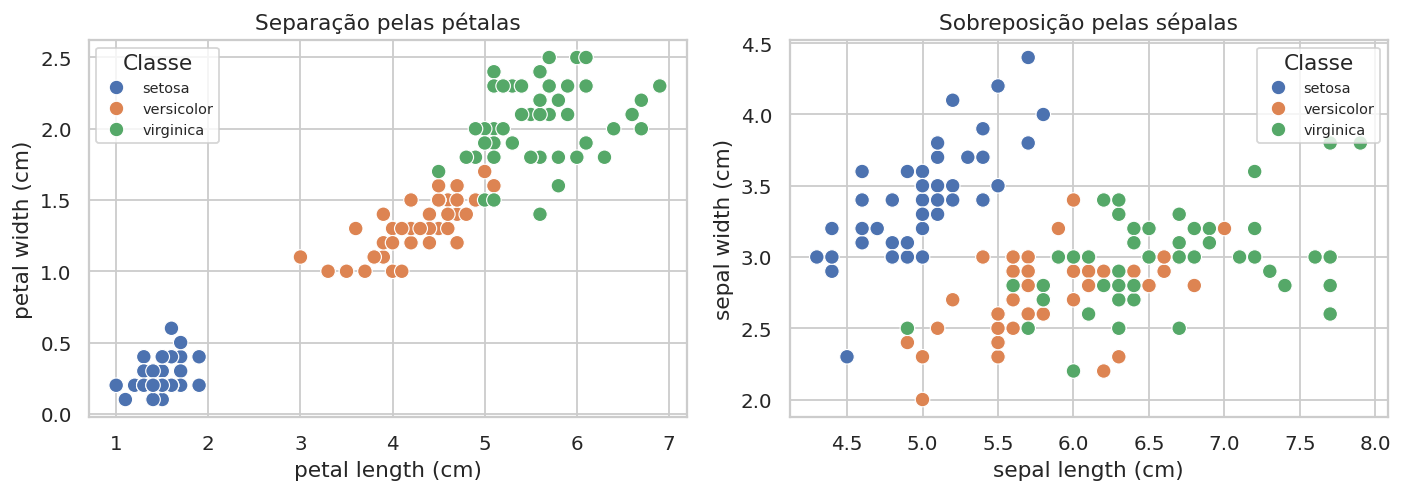

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x="petal length (cm)", y="petal width (cm)", hue="classe", s=65, ax=eixos[0])
eixos[0].set_title("Separação pelas pétalas")
sns.scatterplot(data=df, x="sepal length (cm)", y="sepal width (cm)", hue="classe", s=65, ax=eixos[1])
eixos[1].set_title("Sobreposição pelas sépalas")
for eixo in eixos:
    eixo.legend(title="Classe", fontsize=8)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "distribuicao_iris.png", dpi=180, bbox_inches="tight")
plt.show()

In [4]:
def dividir_dados(semente=SEMENTE):
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        iris.data, iris.target, test_size=0.20, random_state=semente, stratify=iris.target
    )
    X_treino, X_validacao, y_treino, y_validacao = train_test_split(
        X_treino, y_treino, test_size=0.25, random_state=semente, stratify=y_treino
    )
    return X_treino, X_validacao, X_teste, y_treino, y_validacao, y_teste


class Padronizador:
    # Padronização z-score estimada exclusivamente no conjunto de treino.

    def ajustar(self, X):
        self.media = np.mean(X, axis=0)
        self.desvio = np.std(X, axis=0)
        self.desvio[self.desvio == 0] = 1.0
        return self

    def transformar(self, X):
        return (X - self.media) / self.desvio


X_treino, X_validacao, X_teste, y_treino, y_validacao, y_teste = dividir_dados()
print("Treino:", X_treino.shape, "| validação:", X_validacao.shape, "| teste:", X_teste.shape)

Treino: (90, 4) | validação: (30, 4) | teste: (30, 4)


## 2. Depuração da implementação original

Foram identificados quatro problemas principais:

1. `predict` aplicava duas transformações lineares sem a ativação da camada oculta usada no treino;
2. os vieses eram atualizados dentro dos laços de pesos, multiplicando indevidamente cada atualização;
3. o erro da camada oculta era calculado depois da alteração de $W_2$;
4. o acumulador chamado de MSE possuía fatores arbitrários e não media a perda de classificação.

A versão abaixo usa propagação consistente, *softmax* estável na saída, entropia cruzada, atualização vetorizada, inicialização apropriada, mini-lotes, regularização L2 e parada antecipada opcional.

In [5]:
class MLPDoZero:
    def __init__(self, neuronios_ocultos=8, ativacao="tanh", taxa_aprendizado=0.03,
                 epocas=2000, tamanho_lote=16, l2=0.0, paciencia=None, semente=SEMENTE):
        self.neuronios_ocultos = neuronios_ocultos
        self.ativacao_nome = ativacao
        self.taxa_aprendizado = taxa_aprendizado
        self.epocas = epocas
        self.tamanho_lote = tamanho_lote
        self.l2 = l2
        self.paciencia = paciencia
        self.semente = semente

    def _ativar(self, z):
        if self.ativacao_nome == "sigmoide":
            z = np.clip(z, -500, 500)
            return 1.0 / (1.0 + np.exp(-z))
        if self.ativacao_nome == "relu":
            return np.maximum(0.0, z)
        return np.tanh(z)

    def _derivada_ativacao(self, z, a):
        if self.ativacao_nome == "sigmoide":
            return a * (1.0 - a)
        if self.ativacao_nome == "relu":
            return (z > 0).astype(float)
        return 1.0 - a**2

    @staticmethod
    def _softmax(logits):
        logits = logits - np.max(logits, axis=1, keepdims=True)
        exponenciais = np.exp(logits)
        return exponenciais / np.sum(exponenciais, axis=1, keepdims=True)

    @staticmethod
    def _one_hot(y, numero_classes=3):
        alvos = np.zeros((len(y), numero_classes))
        alvos[np.arange(len(y)), y.astype(int)] = 1.0
        return alvos

    def _inicializar(self, numero_entradas, numero_saidas):
        self.gerador = np.random.default_rng(self.semente)
        escala_1 = np.sqrt(2.0 / numero_entradas) if self.ativacao_nome == "relu" else np.sqrt(1.0 / numero_entradas)
        escala_2 = np.sqrt(1.0 / self.neuronios_ocultos)
        self.W1 = self.gerador.normal(0, escala_1, (numero_entradas, self.neuronios_ocultos))
        self.b1 = np.zeros(self.neuronios_ocultos)
        self.W2 = self.gerador.normal(0, escala_2, (self.neuronios_ocultos, numero_saidas))
        self.b2 = np.zeros(numero_saidas)

    def _propagar(self, X):
        z1 = X @ self.W1 + self.b1
        a1 = self._ativar(z1)
        logits = a1 @ self.W2 + self.b2
        probabilidades = self._softmax(logits)
        return z1, a1, probabilidades

    def _calcular_perda(self, X, y):
        probabilidades = self._propagar(X)[2]
        entropia = -np.mean(np.log(np.clip(probabilidades[np.arange(len(y)), y.astype(int)], 1e-12, 1.0)))
        penalidade = 0.5 * self.l2 * (np.sum(self.W1**2) + np.sum(self.W2**2))
        return entropia + penalidade

    def _calcular_gradientes(self, X, y):
        alvos = self._one_hot(y)
        z1, a1, probabilidades = self._propagar(X)
        quantidade = len(X)

        delta_2 = (probabilidades - alvos) / quantidade
        dW2 = a1.T @ delta_2 + self.l2 * self.W2
        db2 = np.sum(delta_2, axis=0)
        delta_1 = (delta_2 @ self.W2.T) * self._derivada_ativacao(z1, a1)
        dW1 = X.T @ delta_1 + self.l2 * self.W1
        db1 = np.sum(delta_1, axis=0)
        return dW1, db1, dW2, db2

    def predizer_probabilidades(self, X):
        return self._propagar(X)[2]

    def predizer(self, X):
        return np.argmax(self.predizer_probabilidades(X), axis=1)

    def ajustar(self, X, y, X_validacao, y_validacao):
        self._inicializar(X.shape[1], len(np.unique(y)))
        self.historico = {
            "perda_treino": [], "perda_validacao": [],
            "acuracia_treino": [], "acuracia_validacao": []
        }
        melhor_perda = np.inf
        melhores_pesos = None
        epocas_sem_melhora = 0

        for epoca in range(self.epocas):
            indices = self.gerador.permutation(len(X))
            for inicio in range(0, len(X), self.tamanho_lote):
                indice_lote = indices[inicio:inicio + self.tamanho_lote]
                X_lote, y_lote = X[indice_lote], y[indice_lote]
                dW1, db1, dW2, db2 = self._calcular_gradientes(X_lote, y_lote)
                self.W1 -= self.taxa_aprendizado * dW1
                self.b1 -= self.taxa_aprendizado * db1
                self.W2 -= self.taxa_aprendizado * dW2
                self.b2 -= self.taxa_aprendizado * db2

            perda_treino = self._calcular_perda(X, y)
            perda_validacao = self._calcular_perda(X_validacao, y_validacao)
            self.historico["perda_treino"].append(perda_treino)
            self.historico["perda_validacao"].append(perda_validacao)
            self.historico["acuracia_treino"].append(np.mean(self.predizer(X) == y))
            self.historico["acuracia_validacao"].append(np.mean(self.predizer(X_validacao) == y_validacao))

            if perda_validacao < melhor_perda - 1e-6:
                melhor_perda = perda_validacao
                melhores_pesos = tuple(valor.copy() for valor in (self.W1, self.b1, self.W2, self.b2))
                self.melhor_epoca = epoca + 1
                epocas_sem_melhora = 0
            else:
                epocas_sem_melhora += 1

            if self.paciencia is not None and epocas_sem_melhora >= self.paciencia:
                break

        self.epocas_executadas = len(self.historico["perda_treino"])
        if melhores_pesos is not None and self.paciencia is not None:
            self.W1, self.b1, self.W2, self.b2 = melhores_pesos
        return self

### Verificação numérica do backpropagation

O gradiente analítico de quatro parâmetros é comparado com uma aproximação por diferenças centrais. Erros relativos muito menores que $10^{-4}$ indicam consistência da derivação e da implementação.

In [6]:
padronizador_teste = Padronizador().ajustar(X_treino)
X_pequeno = padronizador_teste.transformar(X_treino[:6])
y_pequeno = y_treino[:6]
rede_teste = MLPDoZero(neuronios_ocultos=4, ativacao="tanh", l2=0.0, semente=7)
rede_teste._inicializar(4, 3)
gradientes = rede_teste._calcular_gradientes(X_pequeno, y_pequeno)

parametros = [
    ("W1[0,0]", rede_teste.W1, (0, 0), gradientes[0][0, 0]),
    ("b1[0]", rede_teste.b1, (0,), gradientes[1][0]),
    ("W2[0,0]", rede_teste.W2, (0, 0), gradientes[2][0, 0]),
    ("b2[0]", rede_teste.b2, (0,), gradientes[3][0]),
]

linhas = []
epsilon = 1e-5
for nome, vetor, indice, gradiente_analitico in parametros:
    original = vetor[indice]
    vetor[indice] = original + epsilon
    perda_mais = rede_teste._calcular_perda(X_pequeno, y_pequeno)
    vetor[indice] = original - epsilon
    perda_menos = rede_teste._calcular_perda(X_pequeno, y_pequeno)
    vetor[indice] = original
    gradiente_numerico = (perda_mais - perda_menos) / (2 * epsilon)
    erro_relativo = abs(gradiente_analitico - gradiente_numerico) / max(1e-12, abs(gradiente_analitico) + abs(gradiente_numerico))
    linhas.append([nome, gradiente_analitico, gradiente_numerico, erro_relativo])

verificacao_gradientes = pd.DataFrame(linhas, columns=["parâmetro", "analítico", "numérico", "erro relativo"])
display(verificacao_gradientes)
assert verificacao_gradientes["erro relativo"].max() < 1e-4
print("Teste aprovado: gradientes consistentes.")

Teste aprovado: gradientes consistentes.


,parâmetro,analítico,numérico,erro relativo
0,"W1[0,0]",0.006643,0.006643,1.214393e-09
1,b1[0],-0.172108,-0.172108,7.684049e-12
2,"W2[0,0]",-0.032848,-0.032848,4.093520e-11
3,b2[0],0.138045,0.138045,1.812911e-11


## 3. Experimentos de configuração

Comparamos três versões na mesma divisão dos dados. A primeira mantém as principais escolhas do notebook original, mas corrige o backpropagation e a predição. As demais avaliam padronização, funções de ativação, regularização e parada antecipada.

In [7]:
def preparar_divisao(semente, padronizar=True):
    Xt, Xv, Xe, yt, yv, ye = dividir_dados(semente)
    if padronizar:
        padronizador = Padronizador().ajustar(Xt)
        Xt, Xv, Xe = (padronizador.transformar(Xt), padronizador.transformar(Xv), padronizador.transformar(Xe))
    return Xt, Xv, Xe, yt, yv, ye


configuracoes = [
    {
        "nome": "Original corrigida",
        "padronizar": False,
        "parametros": dict(neuronios_ocultos=5, ativacao="sigmoide", taxa_aprendizado=0.005,
                           epocas=3000, tamanho_lote=1, l2=0.0, paciencia=None),
    },
    {
        "nome": "Padronizada + tanh",
        "padronizar": True,
        "parametros": dict(neuronios_ocultos=8, ativacao="tanh", taxa_aprendizado=0.03,
                           epocas=2500, tamanho_lote=16, l2=0.0, paciencia=250),
    },
    {
        "nome": "ReLU + L2 + early stopping",
        "padronizar": True,
        "parametros": dict(neuronios_ocultos=12, ativacao="relu", taxa_aprendizado=0.02,
                           epocas=2500, tamanho_lote=16, l2=1e-3, paciencia=250),
    },
]

resultados_configuracoes = []
modelos_configuracoes = {}
for configuracao in configuracoes:
    Xt, Xv, Xe, yt, yv, ye = preparar_divisao(SEMENTE, configuracao["padronizar"])
    modelo = MLPDoZero(semente=SEMENTE, **configuracao["parametros"]).ajustar(Xt, yt, Xv, yv)
    previsoes = modelo.predizer(Xe)
    resultados_configuracoes.append({
        "configuração": configuracao["nome"],
        "acurácia teste": accuracy_score(ye, previsoes),
        "F1 macro": f1_score(ye, previsoes, average="macro"),
        "épocas executadas": modelo.epocas_executadas,
        "melhor época": modelo.melhor_epoca,
    })
    modelos_configuracoes[configuracao["nome"]] = (modelo, Xt, Xv, Xe, yt, yv, ye)

tabela_configuracoes = pd.DataFrame(resultados_configuracoes)
display(tabela_configuracoes.style.format({"acurácia teste": "{:.3f}", "F1 macro": "{:.3f}"}))

,configuração,acurácia teste,F1 macro,épocas executadas,melhor época
0,Original corrigida,1.000,1.000,3000,808
1,Padronizada + tanh,1.000,1.000,813,563
2,ReLU + L2 + early stopping,1.000,1.000,1091,841


In [8]:
# Quantificação direta do principal bug do notebook original em uma divisão
# na qual a inconsistência entre treino e predição fica particularmente clara.
semente_bug = 42
Xt_original, Xv_original, Xe_original, yt_original, yv_original, ye_original = preparar_divisao(
    semente_bug, padronizar=False
)
modelo_original = MLPDoZero(
    semente=semente_bug,
    **configuracoes[0]["parametros"],
).ajustar(Xt_original, yt_original, Xv_original, yv_original)
previsao_correta = modelo_original.predizer(Xe_original)
saida_sem_ativacao = (Xe_original @ modelo_original.W1 + modelo_original.b1) @ modelo_original.W2 + modelo_original.b2
previsao_com_bug = np.argmax(saida_sem_ativacao, axis=1)

comparacao_bug = pd.DataFrame({
    "implementação": ["Predição corrigida", "Predição original sem ativação"],
    "acurácia": [accuracy_score(ye_original, previsao_correta), accuracy_score(ye_original, previsao_com_bug)],
})
display(comparacao_bug.style.format({"acurácia": "{:.3f}"}))

,implementação,acurácia
0,Predição corrigida,1.000
1,Predição original sem ativação,0.767


## 4. Robustez em diferentes divisões

Uma única divisão pode produzir uma estimativa otimista. Por isso, a configuração final é repetida com dez sementes, sempre com divisão estratificada e sem contato do teste com o treinamento ou a escolha da época.

,semente,acurácia,F1 macro,melhor época
0,0,1.000,1.000,2487
1,1,1.000,1.000,841
2,2,0.967,0.967,2459
3,3,0.867,0.868,1973
4,4,1.000,1.000,570
5,5,0.967,0.967,1296
6,6,0.967,0.967,1234
7,7,1.000,1.000,2402
8,8,0.933,0.933,729
9,9,0.967,0.967,2493


,acurácia,F1 macro
mean,0.9667,0.9668
std,0.0416,0.0412
min,0.8667,0.8682
max,1.0000,1.0000


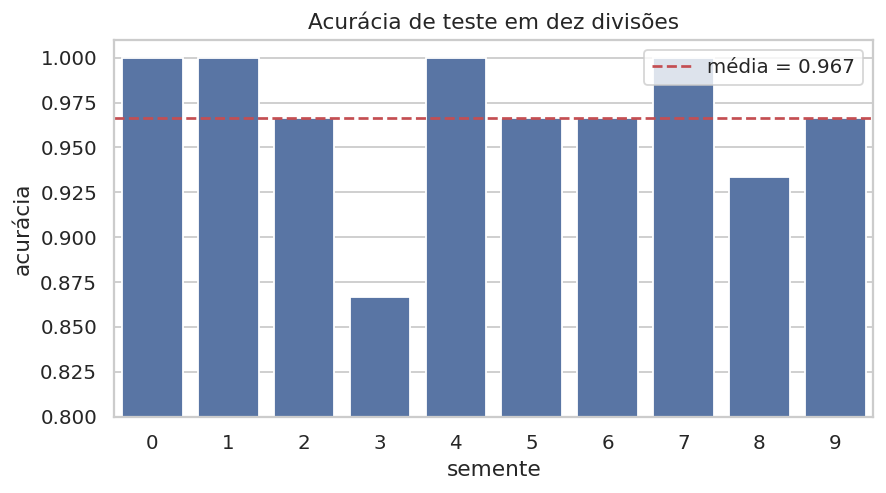

In [9]:
parametros_finais = dict(
    neuronios_ocultos=12, ativacao="relu", taxa_aprendizado=0.02,
    epocas=2500, tamanho_lote=16, l2=1e-3, paciencia=250
)

repeticoes = []
for semente in range(10):
    Xt, Xv, Xe, yt, yv, ye = preparar_divisao(semente, padronizar=True)
    modelo = MLPDoZero(semente=semente, **parametros_finais).ajustar(Xt, yt, Xv, yv)
    previsoes = modelo.predizer(Xe)
    repeticoes.append({
        "semente": semente,
        "acurácia": accuracy_score(ye, previsoes),
        "F1 macro": f1_score(ye, previsoes, average="macro"),
        "melhor época": modelo.melhor_epoca,
    })

tabela_repeticoes = pd.DataFrame(repeticoes)
resumo_repeticoes = tabela_repeticoes[["acurácia", "F1 macro"]].agg(["mean", "std", "min", "max"])
display(tabela_repeticoes.style.format({"acurácia": "{:.3f}", "F1 macro": "{:.3f}"}))
display(resumo_repeticoes.style.format("{:.4f}"))

fig, eixo = plt.subplots(figsize=(7, 4))
sns.barplot(data=tabela_repeticoes, x="semente", y="acurácia", color="#4C72B0", ax=eixo)
eixo.axhline(tabela_repeticoes["acurácia"].mean(), color="#C44E52", linestyle="--",
             label=f"média = {tabela_repeticoes['acurácia'].mean():.3f}")
eixo.set_ylim(0.80, 1.01)
eixo.set_title("Acurácia de teste em dez divisões")
eixo.legend()
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "robustez_dez_sementes.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Modelo final: convergência e erros

A execução com semente 1 é usada para visualização detalhada. A decisão sobre hiperparâmetros foi tomada com validação; o teste é consultado apenas ao final.

In [10]:
Xt, Xv, Xe, yt, yv, ye = preparar_divisao(SEMENTE, padronizar=True)
modelo_final = MLPDoZero(semente=SEMENTE, **parametros_finais).ajustar(Xt, yt, Xv, yv)
previsoes_finais = modelo_final.predizer(Xe)

print(f"Melhor época pela validação: {modelo_final.melhor_epoca}")
print(f"Épocas executadas: {modelo_final.epocas_executadas}")
print(f"Acurácia no teste: {accuracy_score(ye, previsoes_finais):.4f}")
print(f"F1 macro no teste: {f1_score(ye, previsoes_finais, average='macro'):.4f}")
print("\nRelatório por classe:")
print(classification_report(ye, previsoes_finais, target_names=nomes_classes, digits=3))

Melhor época pela validação: 841
Épocas executadas: 1091
Acurácia no teste: 1.0000
F1 macro no teste: 1.0000

Relatório por classe:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30



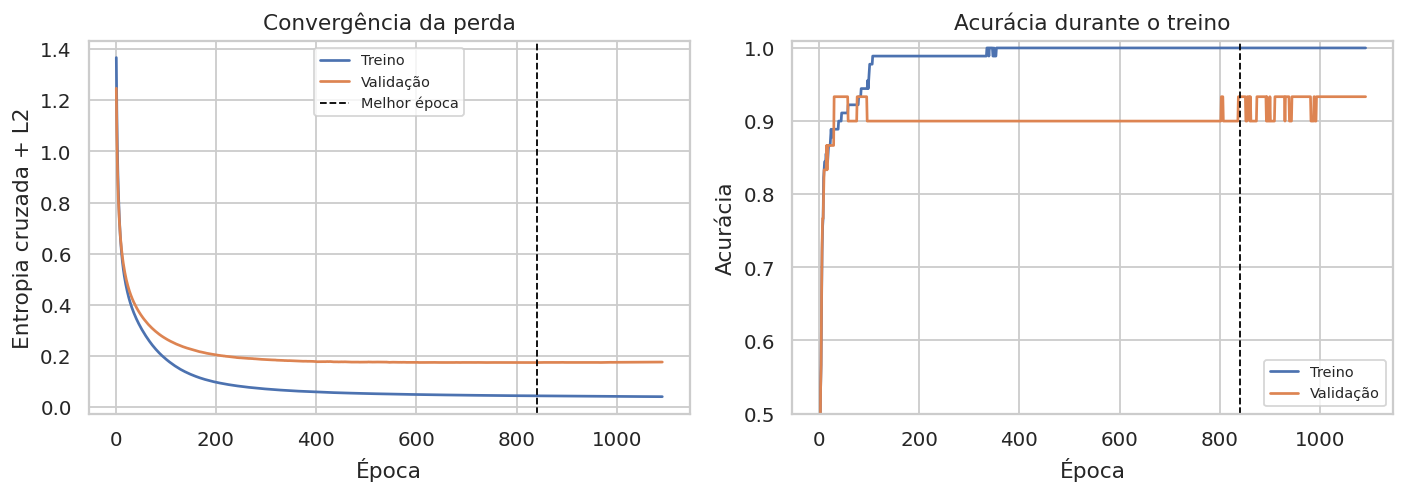

In [11]:
historico = modelo_final.historico
epocas = np.arange(1, len(historico["perda_treino"]) + 1)

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].plot(epocas, historico["perda_treino"], label="Treino")
eixos[0].plot(epocas, historico["perda_validacao"], label="Validação")
eixos[0].axvline(modelo_final.melhor_epoca, color="black", linestyle="--", linewidth=1, label="Melhor época")
eixos[0].set(title="Convergência da perda", xlabel="Época", ylabel="Entropia cruzada + L2")
eixos[0].legend(fontsize=8)

eixos[1].plot(epocas, historico["acuracia_treino"], label="Treino")
eixos[1].plot(epocas, historico["acuracia_validacao"], label="Validação")
eixos[1].axvline(modelo_final.melhor_epoca, color="black", linestyle="--", linewidth=1)
eixos[1].set(title="Acurácia durante o treino", xlabel="Época", ylabel="Acurácia", ylim=(0.5, 1.01))
eixos[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "convergencia_modelo_final.png", dpi=180, bbox_inches="tight")
plt.show()

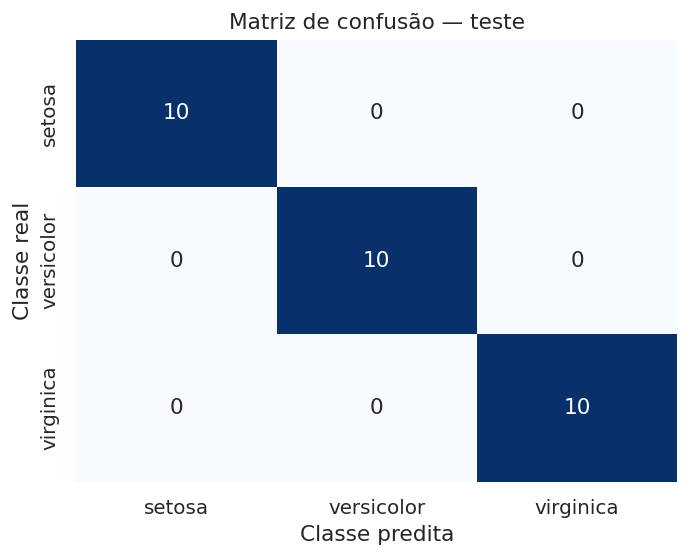

In [12]:
matriz = confusion_matrix(ye, previsoes_finais)
fig, eixo = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixo)
eixo.set(xlabel="Classe predita", ylabel="Classe real", title="Matriz de confusão — teste")
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "matriz_confusao.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Experimento controlado de overfitting

Para tornar o fenômeno visível, treinamos uma rede maior (64 neurônios) com apenas 30 amostras balanceadas, sem regularização e sem parada antecipada. O conjunto de validação permanece inalterado. Espera-se perda de treino próxima de zero, enquanto a perda de validação volta a crescer.

Acurácia de treino: 1.000
Acurácia de validação: 0.933
Menor perda de validação na época: 394
Perda final — treino: 0.0011; validação: 0.3193


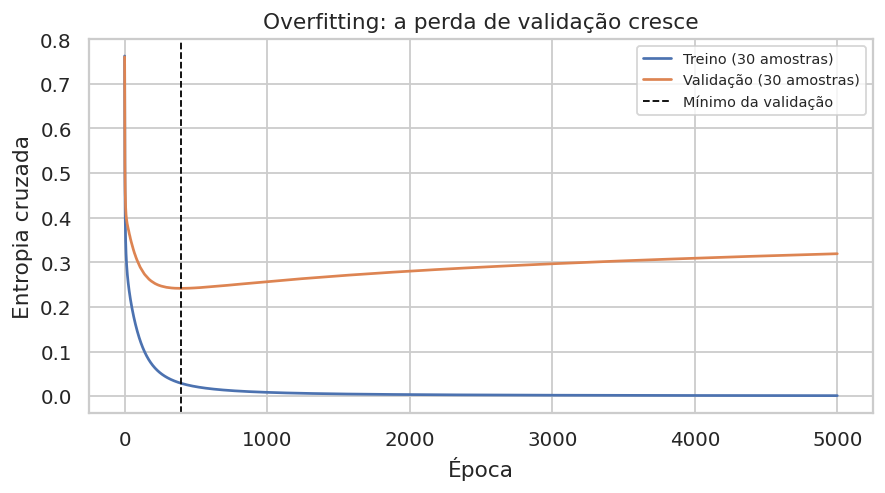

In [13]:
X_treino_bruto, Xv_bruto, _, y_treino_bruto, yv_bruto, _ = dividir_dados(SEMENTE)
indices_reduzidos = np.concatenate([np.where(y_treino_bruto == classe)[0][:10] for classe in range(3)])

padronizador_reduzido = Padronizador().ajustar(X_treino_bruto[indices_reduzidos])
X_reduzido = padronizador_reduzido.transformar(X_treino_bruto[indices_reduzidos])
Xv_reduzido = padronizador_reduzido.transformar(Xv_bruto)
y_reduzido = y_treino_bruto[indices_reduzidos]

modelo_overfit = MLPDoZero(
    neuronios_ocultos=64, ativacao="tanh", taxa_aprendizado=0.03,
    epocas=5000, tamanho_lote=10, l2=0.0, paciencia=None, semente=SEMENTE
).ajustar(X_reduzido, y_reduzido, Xv_reduzido, yv_bruto)

acuracia_treino_overfit = accuracy_score(y_reduzido, modelo_overfit.predizer(X_reduzido))
acuracia_validacao_overfit = accuracy_score(yv_bruto, modelo_overfit.predizer(Xv_reduzido))
print(f"Acurácia de treino: {acuracia_treino_overfit:.3f}")
print(f"Acurácia de validação: {acuracia_validacao_overfit:.3f}")
print(f"Menor perda de validação na época: {modelo_overfit.melhor_epoca}")
print(f"Perda final — treino: {modelo_overfit.historico['perda_treino'][-1]:.4f}; validação: {modelo_overfit.historico['perda_validacao'][-1]:.4f}")

fig, eixo = plt.subplots(figsize=(7, 4))
eixo.plot(modelo_overfit.historico["perda_treino"], label="Treino (30 amostras)")
eixo.plot(modelo_overfit.historico["perda_validacao"], label="Validação (30 amostras)")
eixo.axvline(modelo_overfit.melhor_epoca - 1, color="black", linestyle="--", linewidth=1, label="Mínimo da validação")
eixo.set(title="Overfitting: a perda de validação cresce", xlabel="Época", ylabel="Entropia cruzada")
eixo.legend(fontsize=8)
plt.tight_layout()
plt.savefig(PASTA_RESULTADOS / "overfitting_controlado.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Conclusões

- A principal falha funcional era a inconsistência entre a propagação usada no treino e na predição. Na divisão ilustrativa, esse bug reduziu a acurácia de **100% para cerca de 77%**.
- A combinação de padronização, *softmax* com entropia cruzada, ReLU, regularização L2 e parada antecipada produziu classificação estável das três classes.
- Em dez divisões estratificadas, o modelo final obteve acurácia média próxima de **96,7%**, mostrando que o resultado não depende de uma única separação favorável.
- Os erros remanescentes concentram-se entre *versicolor* e *virginica*, coerente com a sobreposição observada nos atributos; *setosa* é linearmente mais separável.
- O experimento com conjunto reduzido mostra o overfitting: a rede memoriza o treino, mas a perda de validação cresce. Regularização e parada antecipada tratam esse problema.